# West Hawaiʻi: seven-day SST forecasting

ASM540 course-project companion by Drew Baker. This notebook evaluates three satellite cells against persistence and a seasonal baseline.

Install `requirements.txt` with Python 3.12, then run all cells. The notebook uses relative paths. Its final GIF cells assemble the included ArcGIS map frames.

[StoryMap: In Hot Water](https://storymaps.arcgis.com/stories/7e6551719d15418a997e2517c2bc24cc) · [Process log](../../Documentation/PROCESS_LOG.md)


Q3 — Seven-day satellite SST forecasting

Forecast satellite SST seven calendar days after each issue date at the northern, southern nearshore, and southern offshore cells. Compare a random forest regression model with persistence and a seasonal baseline using MAE and RMSE on identical valid dates.

Use 2003–2013 for initial training and 2014 for validation. After selecting settings, refit using eligible 2003–2014 records and evaluate the frozen model during 2015–2025. Every training target must precede the first evaluation issue date. Predictors will use only SST observations and calendar information available at the issue date.

Preserve missing dates on a complete daily calendar and exclude forecast windows crossing gaps. Report performance by cell and target-date DHW categories: below 4, 4 to below 8, and 8 or above °C-weeks. Future DHW values are used only to group evaluation results.


In [1]:
import sys
print(sys.executable)

import pandas as pd
import numpy as np

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)


C:\Purdue_Fall_2026\ASM54000\04_ArcGIS_Projects\Term Project\Analysis\Q3\.venv\Scripts\python.exe


pandas: 3.0.6
NumPy: 2.5.4


In [2]:
from pathlib import Path

# Find the repository root from the notebook folder or repository root.
q3_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "Data" / "dhw_5km" / "northern").is_dir()),
    None
)
if q3_root is None:
    raise FileNotFoundError("Open this notebook from the repository; Data/dhw_5km is required.")

q3_data = q3_root / "Data" / "dhw_5km"
q3_cells = ['northern', 'southern_nearshore', 'southern_offshore']

print("Data folder exists:", q3_data.is_dir())
for q3_cell in q3_cells:
    q3_folder = q3_data / q3_cell
    q3_files = sorted(q3_folder.glob("crw_*csv"))
    print(q3_cell, len(q3_files), "CSV files")


Data folder exists: True
northern 23 CSV files
southern_nearshore 23 CSV files
southern_offshore 23 CSV files


In [3]:
q3_sample_file = q3_data /"northern" / "crw_northern_2003.csv"
q3_sample = pd.read_csv(q3_sample_file)

#display(q3_sample.head())

q3_units = q3_sample["time"].eq("UTC")
q3_sample = q3_sample.loc[~q3_units].copy()

print("Observation rows:", len(q3_sample))

q3_sample["Date_UTC"] = pd.to_datetime(
    q3_sample["time"], utc=True, errors="raise"
)

q3_sample["Date_UTC"] = (
    q3_sample["Date_UTC"]
    .dt.tz_localize(None)
    .dt.normalize()
)

q3_sample["SST_C"] = pd.to_numeric(
    q3_sample["CRW_SST"], errors="raise"
)

display(q3_sample[["Date_UTC", "SST_C"]].head())

Observation rows: 365


,Date_UTC,SST_C
1,2003-01-01,25.54
2,2003-01-02,25.40
3,2003-01-03,25.35
4,2003-01-04,25.48
5,2003-01-05,25.39


In [4]:
def load_crw_file(file_path, cell_name):
    data = pd.read_csv(file_path)
    data = data.loc[data["time"].ne("UTC")].copy()

    data["Date_UTC"] = (
        pd.to_datetime(data["time"], utc=True, errors="raise")
        .dt.tz_localize(None)
        .dt.normalize()
    )

    numeric_columns = [
        "latitude", "longitude", "CRW_SST",
        "CRW_DHW", "CRW_DHW_mask"
    ]

    for column in numeric_columns:
        data[column] = pd.to_numeric(data[column], errors="raise")

    data["SST_C"] = data["CRW_SST"]
    data["DHW_CW"] = data["CRW_DHW"].where(
        data["CRW_DHW_mask"].eq(0)
    )

    data["Cell_Name"] = cell_name
    data["Source_File"] = file_path.name

    return data[
        [
            "Cell_Name", "Date_UTC", "latitude", "longitude",
            "SST_C", "DHW_CW", "CRW_DHW_mask", "Source_File"
        ]
    ]

In [5]:
q3_parts = []

for cell_name in q3_cells:
    annual_files = sorted(
        (q3_data / cell_name).glob(f"crw_{cell_name}_*.csv")
    )

    for file_path in annual_files:
        cleaned_data = load_crw_file(file_path, cell_name)
        q3_parts.append(cleaned_data)

q3_obs = (
    pd.concat(q3_parts, ignore_index=True)
    .sort_values(["Cell_Name", "Date_UTC"])
    .reset_index(drop=True)
)

print("Combined observation rows:", len(q3_obs))

Combined observation rows: 25188


In [6]:
q3_coverage = q3_obs.groupby("Cell_Name").agg(
    Files=("Source_File", "nunique"),
    Observations=("SST_C", "size"),
    First_Date=("Date_UTC", "min"),
    Last_Date=("Date_UTC", "max")
)

display(q3_coverage)

assert not q3_obs.duplicated(
    ["Cell_Name", "Date_UTC"]
).any(), "Duplicate cell-date observations found."

assert np.isfinite(
    q3_obs["SST_C"]
).all(), "Missing or nonfinite SST values found."

print("Coverage and observation checks passed.")

,Files,Observations,First_Date,Last_Date
Cell_Name,,,,
northern,23,8396,2003-01-01,2025-12-31
southern_nearshore,23,8396,2003-01-01,2025-12-31
southern_offshore,23,8396,2003-01-01,2025-12-31


Coverage and observation checks passed.


In [7]:
q3_calendar = pd.date_range(
    start="2003-01-01",
    end="2025-12-31",
    freq="D"
)

q3_index = pd.MultiIndex.from_product(
    [q3_cells, q3_calendar],
    names=["Cell_Name", "Date_UTC"]
)

q3_daily = (
    q3_obs
    .set_index(["Cell_Name", "Date_UTC"])
    .reindex(q3_index)
    .sort_index()
    .reset_index()
)

print("Daily calendar rows:", len(q3_daily))

Daily calendar rows: 25203


In [8]:
q3_daily["Missing_Day"] = q3_daily["SST_C"].isna()

q3_calendar_check = q3_daily.groupby("Cell_Name").agg(
    Calendar_Days=("Date_UTC", "size"),
    Missing_Days=("Missing_Day", "sum")
)

q3_calendar_check["Observed_Days"] = (
    q3_calendar_check["Calendar_Days"]
    - q3_calendar_check["Missing_Days"]
)

display(q3_calendar_check)

display(
    q3_daily.loc[
        q3_daily["Missing_Day"],
        ["Cell_Name", "Date_UTC"]
    ]
)

,Calendar_Days,Missing_Days,Observed_Days
Cell_Name,,,
northern,8401,5,8396
southern_nearshore,8401,5,8396
southern_offshore,8401,5,8396


,Cell_Name,Date_UTC
7699,northern,2024-01-30
7855,northern,2024-07-04
7856,northern,2024-07-05
7857,northern,2024-07-06
7876,northern,2024-07-25
16100,southern_nearshore,2024-01-30
16256,southern_nearshore,2024-07-04
16257,southern_nearshore,2024-07-05
16258,southern_nearshore,2024-07-06
16277,southern_nearshore,2024-07-25


In [9]:
q3_daily["Target_Date"] = (
    q3_daily["Date_UTC"] + pd.Timedelta(days=7)
)

q3_daily["SST_Target_7d"] = (
    q3_daily.groupby("Cell_Name")["SST_C"]
    .shift(-7)
)

q3_daily["DHW_Target_7d"] = (
    q3_daily.groupby("Cell_Name")["DHW_CW"]
    .shift(-7)
)
display(
    q3_daily[
        [
            "Cell_Name", "Date_UTC", "Target_Date",
            "SST_C", "SST_Target_7d", "DHW_Target_7d"
        ]
    ].head()
)

,Cell_Name,Date_UTC,Target_Date,SST_C,SST_Target_7d,DHW_Target_7d
0,northern,2003-01-01,2003-01-08,25.54,25.12,0.0
1,northern,2003-01-02,2003-01-09,25.40,24.98,0.0
2,northern,2003-01-03,2003-01-10,25.35,24.97,0.0
3,northern,2003-01-04,2003-01-11,25.48,24.93,0.0
4,northern,2003-01-05,2003-01-12,25.39,25.00,0.0


In [10]:
q3_sst_by_cell = q3_daily.groupby("Cell_Name")["SST_C"]

for lag in [1, 7, 14, 28]:
    q3_daily[f"SST_Lag{lag}"] = q3_sst_by_cell.shift(lag)

for window in [7, 28]:
    q3_daily[f"SST_Mean{window}"] = (
        q3_sst_by_cell.transform(
            lambda temperatures: temperatures.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

q3_daily["SST_Change7"] = (
    q3_daily["SST_C"] - q3_daily["SST_Lag7"]
)

In [11]:
q3_daily["Target_Season_Day"] = (
    pd.to_datetime(
        q3_daily["Target_Date"].dt.strftime("2000-%m-%d"),
        format="%Y-%m-%d"
    ).dt.dayofyear - 1
)

q3_season_angle = (
    2 * np.pi * q3_daily["Target_Season_Day"] / 366
)

q3_daily["Season_Sin"] = np.sin(q3_season_angle)
q3_daily["Season_Cos"] = np.cos(q3_season_angle)

In [12]:
q3_daily["History_Complete"] = (
    q3_sst_by_cell.transform(
        lambda temperatures: temperatures.rolling(
            window=29,
            min_periods=29
        ).count()
    ).eq(29)
)

q3_daily["Future_Complete"] = q3_daily["SST_C"].notna()

for lead in range(1,8):
    q3_daily["Future_Complete"] = (
        q3_daily["Future_Complete"]
        & q3_sst_by_cell.shift(-lead).notna()
    )

    q3_daily["Eligible"] = (
        q3_daily["History_Complete"]
        & q3_daily["Future_Complete"]
    )

q3_model_data = q3_daily.loc[q3_daily["Eligible"]].copy()

display(
    q3_model_data.groupby("Cell_Name").agg(
        Eligible_Issue_Dates=("Date_UTC", "size"),
        First_Issue_Date=("Date_UTC", "min"),
        Last_Issue_Date=("Date_UTC", "max")
    )
)

,Eligible_Issue_Dates,First_Issue_Date,Last_Issue_Date
Cell_Name,,,
northern,8273,2003-01-29,2025-12-24
southern_nearshore,8273,2003-01-29,2025-12-24
southern_offshore,8273,2003-01-29,2025-12-24


In [13]:
q3_cell_features = []

for cell_name in q3_cells:
    column_name = f"Cell_{cell_name}"

    q3_model_data[column_name] = (
        q3_model_data["Cell_Name"].eq(cell_name).astype(int)
    )

    q3_cell_features.append(column_name)

q3_numeric_features = [
    "SST_C",
    "SST_Lag1",
    "SST_Lag7",
    "SST_Lag14",
    "SST_Lag28",
    "SST_Mean7",
    "SST_Mean28",
    "SST_Change7",
    "Season_Sin",
    "Season_Cos"
]

q3_features = q3_numeric_features + q3_cell_features

print("Number of predictors:", len(q3_features))
print(q3_features)

Number of predictors: 13
['SST_C', 'SST_Lag1', 'SST_Lag7', 'SST_Lag14', 'SST_Lag28', 'SST_Mean7', 'SST_Mean28', 'SST_Change7', 'Season_Sin', 'Season_Cos', 'Cell_northern', 'Cell_southern_nearshore', 'Cell_southern_offshore']


In [14]:
q3_validation_start = pd.Timestamp("2014-01-01")
q3_test_start = pd.Timestamp("2015-01-01")

q3_issue_dates = q3_model_data["Date_UTC"]
q3_target_dates = q3_model_data["Target_Date"]

q3_train = q3_model_data.loc[
    (q3_issue_dates < q3_validation_start)
    & (q3_target_dates < q3_validation_start)
].copy()

q3_validation = q3_model_data.loc[
    (q3_issue_dates >= q3_validation_start)
    & (q3_issue_dates < q3_test_start)
    & (q3_target_dates < q3_test_start)
].copy()

q3_test = q3_model_data.loc[
    q3_issue_dates >= q3_test_start
].copy()

In [15]:
q3_required_values = q3_model_data[
    q3_features + ["SST_Target_7d"]
].to_numpy(dtype=float)

assert np.isfinite(q3_required_values).all(), (
    "Missing or nonfinite predictor or target values."
)

assert (
    q3_train["Target_Date"].max()
    < q3_validation["Date_UTC"].min()
), "Training targets overlap the validation period."

assert (
    q3_validation["Target_Date"].max()
    < q3_test["Date_UTC"].min()
), "Validation targets overlap the test period."

q3_split_summary = []

for split_name, split_data in [
    ("Training", q3_train),
    ("Validation", q3_validation),
    ("Test", q3_test)
]:
    q3_split_summary.append({
        "Split": split_name,
        "Rows": len(split_data),
        "First_Issue": split_data["Date_UTC"].min(),
        "Last_Issue": split_data["Date_UTC"].max(),
        "Last_Target": split_data["Target_Date"].max()
    })

display(pd.DataFrame(q3_split_summary))

,Split,Rows,First_Issue,Last_Issue,Last_Target
0,Training,11949,2003-01-29,2013-12-24,2013-12-31
1,Validation,1074,2014-01-01,2014-12-24,2014-12-31
2,Test,11754,2015-01-01,2025-12-24,2025-12-31


Objective: Predict SST using the average historical temperature within 15 calendar days of the target’s month and day, separately for each cell. Use only observations from the training period.

In [16]:
def fit_seasonal_baseline(daily_data, cutoff):
    history = daily_data.loc[
        (daily_data["Date_UTC"] < cutoff)
        & daily_data["SST_C"].notna(),
        ["Cell_Name", "Date_UTC", "SST_C"]
    ].copy()

    history["Season_Day"] = (
        pd.to_datetime(
            history["Date_UTC"].dt.strftime("2000-%m-%d"),
            format="%Y-%m-%d"
        ).dt.dayofyear - 1
    )

    rows = []

    for cell_name, cell_history in history.groupby("Cell_Name"):
        for season_day in range(366):
            day_gap = (
                cell_history["Season_Day"] - season_day
            ).abs()

            nearby_days = (day_gap <= 15) | (day_gap >= 351)

            rows.append({
                "Cell_Name": cell_name,
                "Target_Season_Day": season_day,
                "Pred_Seasonal": cell_history.loc[
                    nearby_days, "SST_C"
                ].mean()
            })

    return pd.DataFrame(rows)

q3_seasonal_lookup = fit_seasonal_baseline(
    q3_daily, q3_validation_start
)

print("Seasonal lookup rows:", len(q3_seasonal_lookup))

Seasonal lookup rows: 1098


In [17]:
q3_validation_results = q3_validation.merge(
    q3_seasonal_lookup,
    on=["Cell_Name", "Target_Season_Day"],
    how="left",
    validate="many_to_one"
)

q3_validation_results["Pred_Persistence"] = (
    q3_validation_results["SST_C"]
)

q3_baseline_values = q3_validation_results[
    ["Pred_Persistence", "Pred_Seasonal"]
].to_numpy(dtype=float)

assert np.isfinite(q3_baseline_values).all(), (
    "Missing or nonfinite baseline predictions."
)

print("Validation forecasts:", len(q3_validation_results))

Validation forecasts: 1074


In [18]:
def forecast_metrics(observed, predicted):
    errors = (
        np.asarray(predicted, dtype=float)
        - np.asarray(observed, dtype=float)
    )

    return {
        "N": len(errors),
        "MAE_C": np.mean(np.abs(errors)),
        "RMSE_C": np.sqrt(np.mean(errors ** 2))
    }

q3_baseline_rows = []

for model_name, prediction_column in [
    ("Persistence", "Pred_Persistence"),
    ("Seasonal", "Pred_Seasonal")
]:
    scores = forecast_metrics(
        q3_validation_results["SST_Target_7d"],
        q3_validation_results[prediction_column]
    )

    q3_baseline_rows.append({
        "Model": model_name,
        **scores
    })

q3_validation_baselines = pd.DataFrame(q3_baseline_rows)

display(q3_validation_baselines.round(4))

,Model,N,MAE_C,RMSE_C
0,Persistence,1074,0.2202,0.2740
1,Seasonal,1074,0.5575,0.6282


Select settings by lowest 2014 validation MAE; break ties using RMSE, then candidate number.

In [19]:
from sklearn.ensemble import RandomForestRegressor

q3_X_train = q3_train[q3_features]
q3_y_train = q3_train["SST_Target_7d"]

q3_X_validation = q3_validation_results[q3_features]
q3_y_validation = q3_validation_results["SST_Target_7d"]

q3_rf_fixed = {
    "n_estimators": 300,
    "criterion": "squared_error",
    "max_features": 1.0,
    "bootstrap": True,
    "random_state": 540,
    "n_jobs": -1
}

q3_rf_candidates = [
    {"max_depth": 8, "min_samples_leaf": 5},
    {"max_depth": 8, "min_samples_leaf": 20},
    {"max_depth": 16, "min_samples_leaf": 5},
    {"max_depth": 16, "min_samples_leaf": 20}
]

In [20]:
q3_rf_models = {}
q3_rf_rows = []

for candidate_number, settings in enumerate(
    q3_rf_candidates, start=1
):
    model = RandomForestRegressor(
        **q3_rf_fixed,
        **settings
    )

    model.fit(q3_X_train, q3_y_train)

    predictions = model.predict(q3_X_validation)

    scores = forecast_metrics(
        q3_y_validation, predictions
    )

    q3_rf_models[candidate_number] = model

    q3_rf_rows.append({
        "Candidate": candidate_number,
        **settings,
        **scores
    })

    print("Finished candidate", candidate_number)

q3_rf_validation = pd.DataFrame(q3_rf_rows)

display(
    q3_rf_validation.sort_values(
        ["MAE_C", "RMSE_C", "Candidate"]
    ).round(4)
)

Finished candidate 1


Finished candidate 2


Finished candidate 3


Finished candidate 4


,Candidate,max_depth,min_samples_leaf,N,MAE_C,RMSE_C
3,4,16,20,1074,0.2116,0.2652
1,2,8,20,1074,0.2130,0.2663
0,1,8,5,1074,0.2152,0.2700
2,3,16,5,1074,0.2185,0.2757


In [21]:
q3_best_candidate = int(
    q3_rf_validation.sort_values(
        ["MAE_C", "RMSE_C", "Candidate"]
    ).iloc[0]["Candidate"]
)

q3_best_rf = q3_rf_models[q3_best_candidate]
q3_selected_rf_params = q3_best_rf.get_params()

q3_validation_results["Pred_RF"] = (
    q3_best_rf.predict(q3_X_validation)
)

q3_best_scores = forecast_metrics(
    q3_y_validation,
    q3_validation_results["Pred_RF"]
)

q3_validation_comparison = pd.concat(
    [
        q3_validation_baselines,
        pd.DataFrame([
            {"Model": "Random forest", **q3_best_scores}
        ])
    ],
    ignore_index=True
)

print("Selected RF candidate:", q3_best_candidate)

display(
    q3_validation_comparison.sort_values(
        "MAE_C"
    ).round(4)
)

Selected RF candidate: 4


,Model,N,MAE_C,RMSE_C
2,Random forest,1074,0.2116,0.2652
0,Persistence,1074,0.2202,0.2740
1,Seasonal,1074,0.5575,0.6282


In [22]:
q3_development = q3_model_data.loc[
    (q3_model_data["Date_UTC"] < q3_test_start)
    & (q3_model_data["Target_Date"] < q3_test_start)
].copy()

assert (
    q3_development["Target_Date"].max()
    < q3_test["Date_UTC"].min()
), "Development targets overlap the test period."

q3_final_rf = RandomForestRegressor(
    **q3_selected_rf_params
)

q3_final_rf.fit(
    q3_development[q3_features],
    q3_development["SST_Target_7d"]
)

q3_final_seasonal_lookup = fit_seasonal_baseline(
    q3_daily, q3_test_start
)

print("Development forecasts:", len(q3_development))

Development forecasts: 13044


In [23]:
q3_test_results = q3_test.merge(
    q3_final_seasonal_lookup,
    on=["Cell_Name", "Target_Season_Day"],
    how="left",
    validate="many_to_one"
)

q3_test_results["Pred_Persistence"] = (
    q3_test_results["SST_C"]
)

q3_test_results["Pred_RF"] = q3_final_rf.predict(
    q3_test_results[q3_features]
)

q3_prediction_columns = {
    "Persistence": "Pred_Persistence",
    "Seasonal": "Pred_Seasonal",
    "Random forest": "Pred_RF"
}

assert np.isfinite(
    q3_test_results[
        list(q3_prediction_columns.values())
    ].to_numpy(dtype=float)
).all(), "Missing or nonfinite test predictions."

q3_test_rows = []

for model_name, prediction_column in q3_prediction_columns.items():
    scores = forecast_metrics(
        q3_test_results["SST_Target_7d"],
        q3_test_results[prediction_column]
    )

    q3_test_rows.append({
        "Model": model_name,
        **scores
    })

    q3_test_comparison = pd.DataFrame(q3_test_rows)

    display(
        q3_test_comparison.sort_values("MAE_C").round(4)
    )

,Model,N,MAE_C,RMSE_C
0,Persistence,11754,0.2228,0.2817


,Model,N,MAE_C,RMSE_C
0,Persistence,11754,0.2228,0.2817
1,Seasonal,11754,0.5656,0.7070


,Model,N,MAE_C,RMSE_C
0,Persistence,11754,0.2228,0.2817
2,Random forest,11754,0.2350,0.3135
1,Seasonal,11754,0.5656,0.7070


Investigation

In [24]:
def summarize_forecasts(data, group_columns, prediction_columns):
    rows = []

    for group_key, group in data.groupby(
        group_columns, observed=True, dropna=False
    ):
        if not isinstance(group_key, tuple):
            group_key = (group_key,)

        group_labels = dict(zip(group_columns, group_key))

        for model_name, prediction_column in prediction_columns.items():
            scores = forecast_metrics(
                group["SST_Target_7d"],
                group[prediction_column]
            )

            rows.append({
                **group_labels,
                "Model": model_name,
                **scores
            })
    return pd.DataFrame(rows)

q3_test_by_cell = summarize_forecasts(
    q3_test_results,
    ["Cell_Name"],
    q3_prediction_columns
)

display(q3_test_by_cell.round(4))

,Cell_Name,Model,N,MAE_C,RMSE_C
0,northern,Persistence,3918,0.2244,0.2856
1,northern,Seasonal,3918,0.5386,0.6809
2,northern,Random forest,3918,0.2175,0.2833
3,southern_nearshore,Persistence,3918,0.2214,0.2792
4,southern_nearshore,Seasonal,3918,0.5775,0.7185
5,southern_nearshore,Random forest,3918,0.2431,0.3269
6,southern_offshore,Persistence,3918,0.2226,0.2803
7,southern_offshore,Seasonal,3918,0.5808,0.7209
8,southern_offshore,Random forest,3918,0.2444,0.3281


In [25]:
q3_test_results["DHW_Class"] = pd.cut(
    q3_test_results["DHW_Target_7d"],
    bins=[0, 4, 8, np.inf],
    labels=["Below 4", "4 to below 8", "8 or above"],
    right=False
)

q3_test_results["DHW_Class"] = (
    q3_test_results["DHW_Class"]
    .cat.add_categories(["No valid DHW"])
    .fillna("No valid DHW")
)

display(
    q3_test_results["DHW_Class"]
    .value_counts(sort=False)
    .rename("Forecasts")
)

q3_test_by_dhw = summarize_forecasts(
    q3_test_results,
    ["DHW_Class"],
    q3_prediction_columns
)

display(q3_test_by_dhw.round(4))

DHW_Class
Below 4         11168
4 to below 8      259
8 or above        327
No valid DHW        0
Name: Forecasts, dtype: int64

,DHW_Class,Model,N,MAE_C,RMSE_C
0,Below 4,Persistence,11168,0.2209,0.2787
1,Below 4,Seasonal,11168,0.5236,0.6456
2,Below 4,Random forest,11168,0.2214,0.2843
3,4 to below 8,Persistence,259,0.2337,0.3062
4,4 to below 8,Seasonal,259,1.4322,1.5323
5,4 to below 8,Random forest,259,0.5392,0.7243
6,8 or above,Persistence,327,0.2779,0.3547
7,8 or above,Seasonal,327,1.3128,1.3686
8,8 or above,Random forest,327,0.4594,0.5967


In [26]:
q3_test_results["Target_Year"] = (
    q3_test_results["Target_Date"].dt.year
)

q3_test_by_year = summarize_forecasts(
    q3_test_results,
    ["Target_Year"],
    q3_prediction_columns
)

q3_yearly_mae = q3_test_by_year.pivot(
    index="Target_Year",
    columns ="Model",
    values="MAE_C"
)

q3_yearly_mae["RF_Skill_Pct"] = 100 * (
    1
    - q3_yearly_mae["Random forest"]
    / q3_yearly_mae["Persistence"].replace(0, np.nan)
)

q3_yearly_counts = (
    q3_test_results.groupby("Target_Year").size()
)

q3_yearly_mae.insert(0, "N", q3_yearly_counts)

display(q3_yearly_mae.round(4))

Model,N,Persistence,Random forest,Seasonal,RF_Skill_Pct
Target_Year,,,,,
2015,1074,0.2604,0.3805,0.8709,-46.1326
2016,1098,0.2405,0.2215,0.6095,7.9059
2017,1095,0.2341,0.2167,0.6060,7.4176
2018,1095,0.2382,0.2379,0.6371,0.1451
2019,1095,0.2313,0.3321,1.0111,-43.5643
2020,1098,0.2030,0.1795,0.4613,11.5561
2021,1095,0.2496,0.2454,0.3716,1.7000
2022,1095,0.1981,0.1864,0.4566,5.9085
2023,1095,0.2159,0.1955,0.3221,9.4431


In [27]:
q3_test_results["Error_RF_C"] = (
    q3_test_results["Pred_RF"]
    - q3_test_results["SST_Target_7d"]
)

q3_test_results["Error_Persistence_C"] = (
    q3_test_results["Pred_Persistence"]
    -q3_test_results["SST_Target_7d"]
)

q3_bias_by_dhw = q3_test_results.groupby(
    "DHW_Class", observed=True
).agg(
    N=("Error_RF_C", "size"),
    RF_Mean_Error_C=("Error_RF_C", "mean"),
    Persistence_Mean_Error_C=("Error_Persistence_C", "mean")
)

display(q3_bias_by_dhw.round(4))

,N,RF_Mean_Error_C,Persistence_Mean_Error_C
DHW_Class,,,
Below 4,11168,-0.0648,-0.0107
4 to below 8,259,-0.4511,0.1419
8 or above,327,-0.3765,0.1806


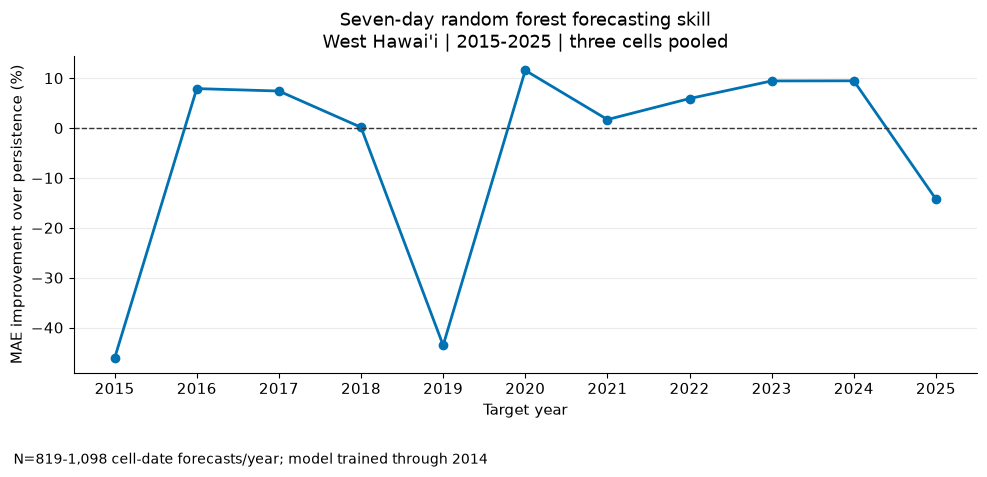

In [28]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})

q3_colors = {
    "Random forest": "#0072B2",
    "Persistence": "#D55E00",
    "Seasonal": "#666666"
}

q3_figures = q3_root / "Documentation" / "Figures"
q3_figures.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4.8))

ax.plot(
    q3_yearly_mae.index,
    q3_yearly_mae["RF_Skill_Pct"],
    color=q3_colors["Random forest"],
    marker="o",
    linewidth=2
)

ax.axhline(0, color="#333333", linestyle="--", linewidth=1)
ax.set_xticks(q3_yearly_mae.index)
ax.set_xlabel("Target year")
ax.set_ylabel("MAE improvement over persistence (%)")
ax.set_title(
    "Seven-day random forest forecasting skill\n"
    "West Hawai'i | 2015-2025 | three cells pooled"
)

ax.grid(axis="y", alpha=.25)

fig.text(
    .02, .02,
    f"N={q3_yearly_mae["N"].min():,}-"
    f"{q3_yearly_mae["N"].max():,} cell-date forecasts/year; "
    "model trained through 2014",
    fontsize=10
)

fig.tight_layout(rect=(0, .08, 1, 1))
fig.savefig(
    q3_figures / "Q3_RF_skill_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

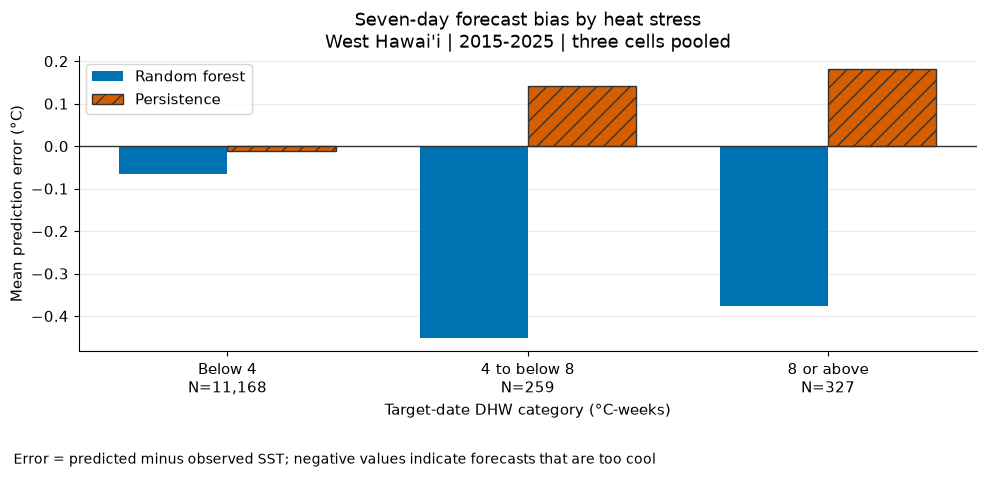

In [29]:
positions = np.arange(len(q3_bias_by_dhw))
bar_width = .36

fig, ax = plt.subplots(figsize=(10, 4.8))

ax.bar(
    positions - bar_width / 2,
    q3_bias_by_dhw["RF_Mean_Error_C"],
    width=bar_width,
    color=q3_colors["Random forest"],
    label="Random forest"
)

ax.bar(
    positions +bar_width /2,
    q3_bias_by_dhw["Persistence_Mean_Error_C"],
    width=bar_width,
    color=q3_colors["Persistence"],
    hatch="//",
    edgecolor="#333333",
    label="Persistence"
)

category_labels = [
    f"{category}\nN={count:,}"
    for category, count in zip(
        q3_bias_by_dhw.index,
        q3_bias_by_dhw["N"]
    )
]

ax.set_xticks(positions, category_labels)
ax.axhline(0, color="#333333", linewidth=1)
ax.set_xlabel("Target-date DHW category (°C-weeks)")
ax.set_ylabel("Mean prediction error (°C)")
ax.set_title(
    "Seven-day forecast bias by heat stress\n"
    "West Hawai'i | 2015-2025 | three cells pooled"
)

ax.legend()
ax.grid(axis="y", alpha=.25)
ax.set_axisbelow(True)

fig.text(
    .02, .02,
    "Error = predicted minus observed SST; "
    "negative values indicate forecasts that are too cool",
    fontsize=10
)

fig.tight_layout(rect=(0, .08, 1, 1))
fig.savefig(
    q3_figures / "Q3_bias_by_DHW.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [30]:
q3_map_metrics = q3_test_by_cell.pivot(
    index="Cell_Name",
    columns="Model",
    values=["N", "MAE_C", "RMSE_C"]
)

q3_map_summary = pd.DataFrame({
    "N_Forecasts": q3_map_metrics[
        ("N", "Random forest")
    ].astype(int),
    "RF_MAE_C": q3_map_metrics[("MAE_C", "Random forest")],
    "Persist_MAE_C": q3_map_metrics[("MAE_C", "Persistence")],
    "Season_MAE_C": q3_map_metrics[("MAE_C", "Seasonal")],
    "RF_RMSE_C": q3_map_metrics[("RMSE_C", "Random forest")],
    "Persist_RMSE_C": q3_map_metrics[("RMSE_C", "Persistence")],
    "Season_RMSE_C": q3_map_metrics[("RMSE_C", "Seasonal")]
})

q3_map_summary["RF_Skill_Pct"] = 100 * (
    1
    - q3_map_summary["RF_MAE_C"]
    / q3_map_summary["Persist_MAE_C"].replace(0, np.nan)
)
q3_map_summary = q3_map_summary.reset_index()

display(q3_map_summary.round(4))

,Cell_Name,N_Forecasts,RF_MAE_C,Persist_MAE_C,Season_MAE_C,RF_RMSE_C,Persist_RMSE_C,Season_RMSE_C,RF_Skill_Pct
0,northern,3918,0.2175,0.2244,0.5386,0.2833,0.2856,0.6809,3.0974
1,southern_nearshore,3918,0.2431,0.2214,0.5775,0.3269,0.2792,0.7185,-9.8305
2,southern_offshore,3918,0.2444,0.2226,0.5808,0.3281,0.2803,0.7209,-9.8132


In [31]:
q3_coordinate_counts = q3_obs.groupby("Cell_Name")[
    ["latitude", "longitude"]
].nunique(dropna=False)

assert q3_coordinate_counts.eq(1).all().all(), (
    "Coordinates vary within a forecast cell."
)

q3_locations = q3_obs[
    ["Cell_Name", "latitude", "longitude"]
].drop_duplicates()

q3_map_export = q3_map_summary.merge(
    q3_locations,
    on="Cell_Name",
    how="left",
    validate="one_to_one"
)

assert q3_map_export[
    ["latitude", "longitude"]
].notna().all().all(), "Missing cell coordinates."

q3_map_export["Test_Years"] = "2015-2025"
q3_map_export["Horizon_Days"] = 7

q3_export_folder = q3_root / "Analysis" / "Q3" / "Outputs"
q3_export_folder.mkdir(parents=True, exist_ok=True)

q3_map_csv = q3_export_folder / "Q3_CellForecast_Summary.csv"

q3_map_export.to_csv(
    q3_map_csv,
    index=False,
    encoding="utf-8-sig"
)

print(q3_map_csv)

display(
    q3_map_export[
        [
            "Cell_Name", "latitude", "longitude",
            "N_Forecasts", "RF_Skill_Pct"
        ]
    ].round(4)
)

C:\Projects\Active\West-Hawaii-Heat-Stress-ASM540\Analysis\Q3\Outputs\Q3_CellForecast_Summary.csv


,Cell_Name,latitude,longitude,N_Forecasts,RF_Skill_Pct
0,northern,20.275,-155.875,3918,3.0974
1,southern_nearshore,19.225,-155.875,3918,-9.8305
2,southern_offshore,19.225,-155.925,3918,-9.8132


In [32]:
q3_dhw8_rows = q3_test_results.loc[
    q3_test_results["DHW_Class"].eq("8 or above")
].copy()

q3_dhw8_by_cell = summarize_forecasts(
    q3_dhw8_rows,
    ["Cell_Name"],
    q3_prediction_columns
)

print("High-heat forecast rows:", len(q3_dhw8_rows))
display(q3_dhw8_by_cell.round(4))

High-heat forecast rows: 327


,Cell_Name,Model,N,MAE_C,RMSE_C
0,northern,Persistence,56,0.2927,0.3608
1,northern,Seasonal,56,1.2663,1.2856
2,northern,Random forest,56,0.2409,0.2873
3,southern_nearshore,Persistence,135,0.2756,0.3543
4,southern_nearshore,Seasonal,135,1.3202,1.3835
5,southern_nearshore,Random forest,135,0.5040,0.6423
6,southern_offshore,Persistence,136,0.2740,0.3527
7,southern_offshore,Seasonal,136,1.3246,1.3866
8,southern_offshore,Random forest,136,0.5052,0.6423


In [33]:
q3_dhw8_metrics = q3_dhw8_by_cell.pivot(
    index="Cell_Name",
    columns="Model",
    values=["N", "MAE_C", "RMSE_C"]
)

q3_dhw8_map = pd.DataFrame({
    "N_DHW8": q3_dhw8_metrics[("N", "Random forest")].astype(int),
    "RF_MAE_DHW8": q3_dhw8_metrics[("MAE_C", "Random forest")],
    "Persist_MAE_DHW8": q3_dhw8_metrics[("MAE_C", "Persistence")],
    "Season_MAE_DHW8": q3_dhw8_metrics[("MAE_C", "Seasonal")],
    "RF_RMSE_DHW8": q3_dhw8_metrics[("RMSE_C", "Random forest")],
    "Persist_RMSE_DHW8": q3_dhw8_metrics[("RMSE_C", "Persistence")],
    "Season_RMSE_DHW8": q3_dhw8_metrics[("RMSE_C", "Seasonal")]
})

q3_dhw8_map["RF_Skill_DHW8_Pct"] = 100 * (
    1
    - q3_dhw8_map["RF_MAE_DHW8"]
    / q3_dhw8_map["Persist_MAE_DHW8"].replace(0, np.nan)
)

q3_dhw8_map = q3_dhw8_map.reset_index()

assert set(q3_dhw8_map["Cell_Name"]) == set(
    q3_map_summary["Cell_Name"]
), "High-heat cells do not match the overall summary."

assert q3_dhw8_map["N_DHW8"].sum() == len(q3_dhw8_rows), (
    "High-heat forecast counts do not reconcile."
)

display(q3_dhw8_map.round(4))

,Cell_Name,N_DHW8,RF_MAE_DHW8,Persist_MAE_DHW8,Season_MAE_DHW8,RF_RMSE_DHW8,Persist_RMSE_DHW8,Season_RMSE_DHW8,RF_Skill_DHW8_Pct
0,northern,56,0.2409,0.2927,1.2663,0.2873,0.3608,1.2856,17.6775
1,southern_nearshore,135,0.5040,0.2756,1.3202,0.6423,0.3543,1.3835,-82.8439
2,southern_offshore,136,0.5052,0.2740,1.3246,0.6423,0.3527,1.3866,-84.3494


In [34]:
q3_dhw8_map["Test_Years"] = "2015-2025"
q3_dhw8_map["Horizon_Days"] = 7
q3_dhw8_map["DHW_Threshold"] = 8

q3_dhw8_csv = (
    q3_export_folder / "Q3_CellForecast_DHW8_Summary.csv"
)

q3_dhw8_map.to_csv(
    q3_dhw8_csv,
    index=False,
    encoding="utf-8-sig"
)

print(q3_dhw8_csv)

C:\Projects\Active\West-Hawaii-Heat-Stress-ASM540\Analysis\Q3\Outputs\Q3_CellForecast_DHW8_Summary.csv


In [35]:
q3_annual_scores = summarize_forecasts(
    q3_test_results,
    ["Cell_Name", "Target_Year"],
    q3_prediction_columns
)

print("Annual model-summary rows:", len(q3_annual_scores))

display(
    q3_annual_scores.loc[
        q3_annual_scores["Target_Year"].isin([2015, 2019])
    ].round(4)
)

Annual model-summary rows: 99


,Cell_Name,Target_Year,Model,N,MAE_C,RMSE_C
0,northern,2015,Persistence,358,0.2762,0.3425
1,northern,2015,Seasonal,358,0.8451,1.0400
2,northern,2015,Random forest,358,0.3165,0.4340
12,northern,2019,Persistence,365,0.2381,0.3032
13,northern,2019,Seasonal,365,0.9725,1.1196
14,northern,2019,Random forest,365,0.2636,0.3274
33,southern_nearshore,2015,Persistence,358,0.2518,0.3149
34,southern_nearshore,2015,Seasonal,358,0.8831,1.0777
35,southern_nearshore,2015,Random forest,358,0.4120,0.5654
45,southern_nearshore,2019,Persistence,365,0.2278,0.2847


In [36]:
q3_annual_metrics = q3_annual_scores.pivot(
    index=["Cell_Name", "Target_Year"],
    columns="Model",
    values=["N", "MAE_C", "RMSE_C"]
)

q3_annual_map = pd.DataFrame({
    "N_Forecasts": q3_annual_metrics[("N", "Random forest")].astype(int),
    "RF_MAE_C": q3_annual_metrics[("MAE_C", "Random forest")],
    "Persist_MAE_C": q3_annual_metrics[("MAE_C", "Persistence")],
    "Season_MAE_C": q3_annual_metrics[("MAE_C", "Seasonal")],
    "RF_RMSE_C": q3_annual_metrics[("RMSE_C", "Random forest")],
    "Persist_RMSE_C": q3_annual_metrics[("RMSE_C", "Persistence")],
    "Season_RMSE_C": q3_annual_metrics[("RMSE_C", "Seasonal")]
})

q3_annual_map["RF_Skill_Pct"] = 100 * (
    1
    - q3_annual_map["RF_MAE_C"]
    / q3_annual_map["Persist_MAE_C"].replace(0, np.nan)
)

q3_annual_map = q3_annual_map.reset_index()

assert len(q3_annual_map) == 33, "Unexpected cell-year count."

assert not q3_annual_map.duplicated(
    ["Cell_Name", "Target_Year"]
).any(), "Duplicate cell-year summaries."

display(
    q3_annual_map.loc[
        q3_annual_map["Target_Year"].isin([2015, 2019]),
        [
            "Cell_Name", "Target_Year", "N_Forecasts",
            "RF_MAE_C", "Persist_MAE_C", "RF_Skill_Pct"
        ]
    ].round(4)
)

,Cell_Name,Target_Year,N_Forecasts,RF_MAE_C,Persist_MAE_C,RF_Skill_Pct
0,northern,2015,358,0.3165,0.2762,-14.5862
4,northern,2019,365,0.2636,0.2381,-10.7118
11,southern_nearshore,2015,358,0.4120,0.2518,-63.5826
15,southern_nearshore,2019,365,0.3664,0.2278,-60.8785
22,southern_offshore,2015,358,0.4129,0.2530,-63.2058
26,southern_offshore,2019,365,0.3663,0.2281,-60.5599


In [37]:
q3_annual_heat = q3_test_results.groupby(
    ["Cell_Name", "Target_Year"],
    observed=True
).agg(
    N_Valid_DHW=("DHW_Target_7d", "count"),
    Peak_DHW_CW=("DHW_Target_7d", "max"),
    Days_GE4=("DHW_Target_7d", lambda values: values.ge(4).sum()),
    Days_GE8=("DHW_Target_7d", lambda values: values.ge(8).sum())
).reset_index()

q3_annual_export = q3_annual_map.merge(
    q3_annual_heat,
    on=["Cell_Name", "Target_Year"],
    how="left",
    validate="one_to_one"
).sort_values(["Target_Year", "Cell_Name"])

assert q3_annual_export["N_Forecasts"].sum() == 11754
assert q3_annual_export["Days_GE8"].sum() == 327

q3_annual_csv = (
    q3_export_folder / "Q3_CellForecast_Annual_Summary.csv"
)

q3_annual_export.to_csv(
    q3_annual_csv,
    index=False,
    encoding="utf-8-sig"
)

print(q3_annual_csv)
print("Exported cell-year rows:", len(q3_annual_export))


C:\Projects\Active\West-Hawaii-Heat-Stress-ASM540\Analysis\Q3\Outputs\Q3_CellForecast_Annual_Summary.csv
Exported cell-year rows: 33


In [38]:
from pathlib import Path
from PIL import Image as PILImage

q3_gif_frame_root = q3_root / "Documentation" / "Figures" / "Q3_Annual_Frames"

q3_gif_years = list(range(2015, 2026))
q3_gif_frames = {}

for region in ("North", "South"):
    frames = []

    for year in q3_gif_years:
        file = q3_gif_frame_root / region / f"Q3_{region}_{year}.png"
        assert file.is_file(), f"Missing frame: {file}"

        with PILImage.open(file) as source:
            frames.append(source.convert("RGB"))

    q3_gif_frames[region] = frames
    print(f"{region}: loaded {len(frames)} frames.")

q3_frame_sizes = {
    frame.size
    for frames in q3_gif_frames.values()
    for frame in frames
}

assert len(q3_frame_sizes) == 1, "Frame dimensions do not match."
print(f"Frame dimensions: {next(iter(q3_frame_sizes))}")

North: loaded 11 frames.


South: loaded 11 frames.
Frame dimensions: (1650, 1275)


In [39]:
# Sample every frame to build one shared GIF palette.
q3_palette_sheet = PILImage.new(
    "RGB",
    (660, 255 * len(q3_gif_years)),
    "white",
)

for column, frames in enumerate(q3_gif_frames.values()):
    for row, frame in enumerate(frames):
        thumbnail = frame.resize(
            (330, 255),
            PILImage.Resampling.LANCZOS,
        )
        q3_palette_sheet.paste(
            thumbnail,
            (column * 330, row * 255),
        )

q3_gif_palette = q3_palette_sheet.quantize(
    colors=256,
    method=PILImage.Quantize.MEDIANCUT,
)

# Use 2.5 seconds per year, with longer pauses at the ends.
q3_gif_durations = [2500] * len(q3_gif_years)
q3_gif_durations[0] = 4000
q3_gif_durations[-1] = 4000

q3_gif_paths = {}

for region, frames in q3_gif_frames.items():
    indexed_frames = [
        frame.quantize(
            palette=q3_gif_palette,
            dither=PILImage.Dither.NONE,
        )
        for frame in frames
    ]

    output = (
        q3_gif_frame_root.parent
        / f"Q3_Annual_{region}_2015_2025.gif"
    )

    indexed_frames[0].save(
        output,
        save_all=True,
        append_images=indexed_frames[1:],
        palette=bytes(q3_gif_palette.getpalette()),
        duration=q3_gif_durations,
        loop=0,
        disposal=2,
        optimize=False,
    )

    q3_gif_paths[region] = output
    print(f"Saved: {output}")

Saved: C:\Projects\Active\West-Hawaii-Heat-Stress-ASM540\Documentation\Figures\Q3_Annual_North_2015_2025.gif


Saved: C:\Projects\Active\West-Hawaii-Heat-Stress-ASM540\Documentation\Figures\Q3_Annual_South_2015_2025.gif


North: 11 frames verified.


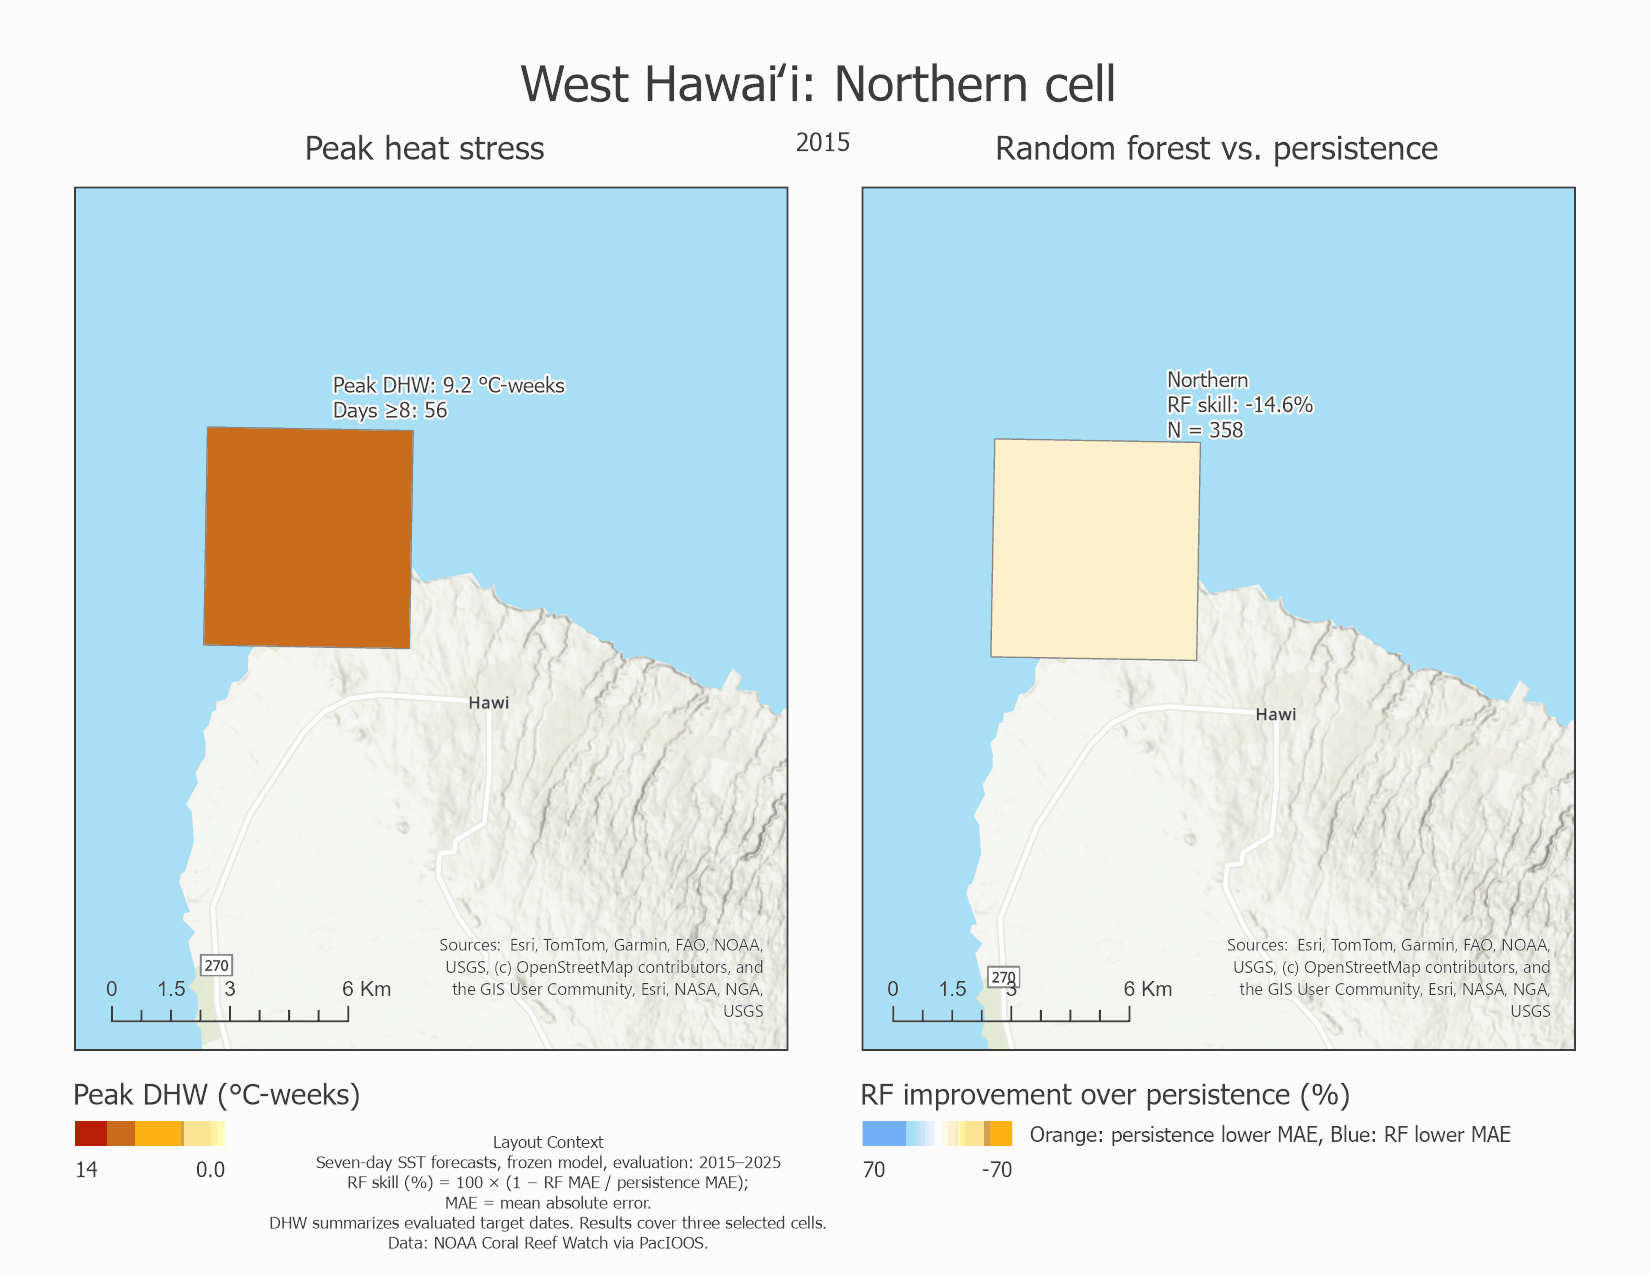

South: 11 frames verified.


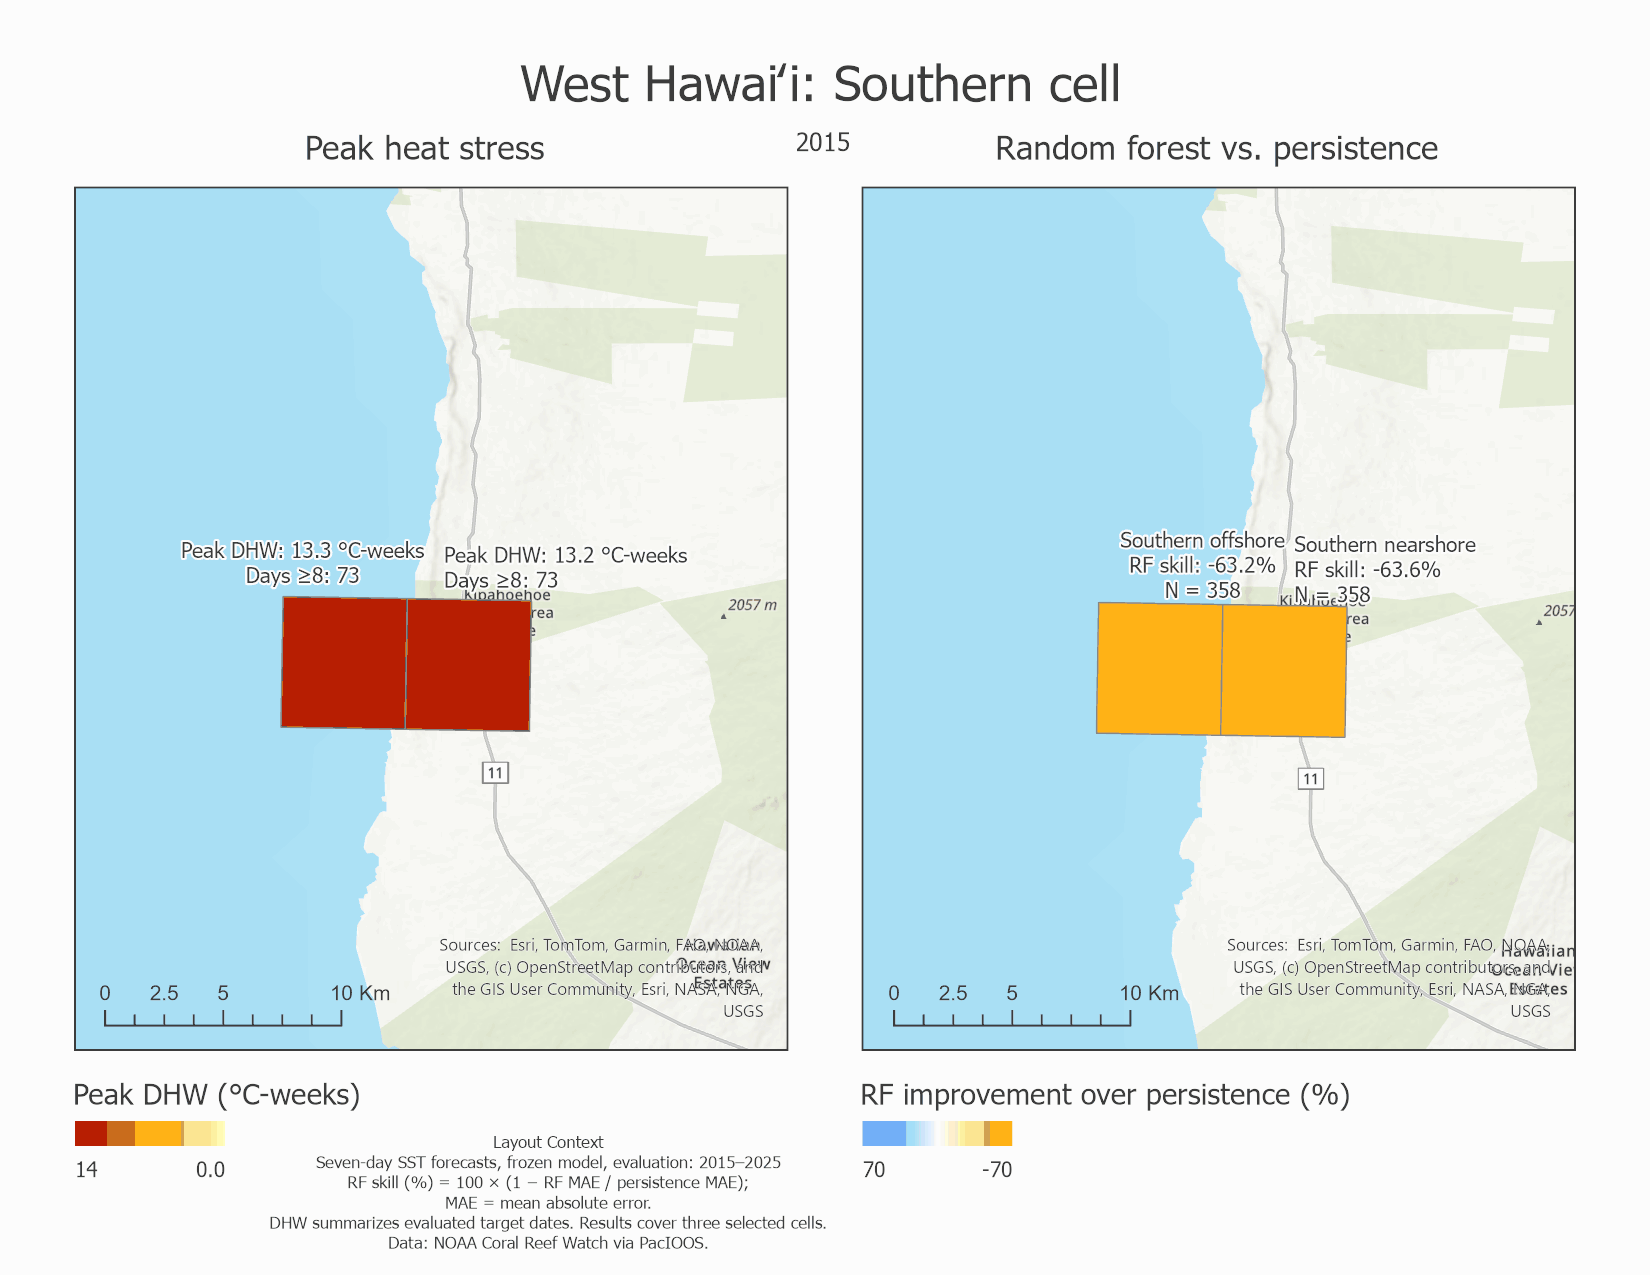

In [40]:
from IPython.display import Image as NotebookImage, display

for region, path in q3_gif_paths.items():
    with PILImage.open(path) as gif:
        assert gif.n_frames == 11, f"{region}: incorrect frame count"
        assert gif.size == q3_gif_frames[region][0].size
        assert gif.info.get("loop") == 0

        actual_durations = []

        for frame_number in range(gif.n_frames):
            gif.seek(frame_number)
            gif.load()
            actual_durations.append(gif.info.get("duration"))

        assert actual_durations == q3_gif_durations

    print(f"{region}: 11 frames verified.")
    display(NotebookImage(filename=str(path), width=1100))